## Entidades por Documento

In [1]:
import json 
with open("./dev.json", "r") as file:
    articulos = json.load(file)

In [2]:
analisis = {}
totales = {}
for pmid, articulo in articulos.items():
    entidades = {}
    for entidad in articulo["entities"]:
        *_, label, _ = entidad.values()
        if label not in entidades:
            entidades[label] = 1
        else:
            entidades[label] += 1
        if label not in totales: 
            totales[label] = 1
        else: totales[label] += 1
    analisis[pmid] = entidades

In [3]:
from collections import Counter
from sklearn.model_selection import train_test_split
import random
from sklearn.model_selection import train_test_split

doc_ids = list(articulos.keys())
splits = {}
desv_seed = []
val_ids, test_ids = train_test_split(
    doc_ids,
    test_size=0.5,
    random_state=21,
    shuffle=True
)

val_docs = {k: articulos[k] for k in val_ids}
test_docs = {k: articulos[k] for k in test_ids}
def count_labels(docs):
    counter = Counter()

    for pmid, doc in docs.items():
        for ent in doc["entities"]:
            counter[ent["label"]] += 1

    return counter
def label_percentages(counter):
    total = sum(counter.values())
    return {
        k: (round(v / total * 100, 2),v)
        for k, v in counter.items()
    }

    
perc_val = label_percentages(count_labels(val_docs))
perc_test = label_percentages(count_labels(test_docs))
desviaciones = {}
for label, (perc, total) in perc_val.items():
    diff = round(abs(perc - perc_test[label][0]), 2)
    desviaciones[label] = (diff, total, perc_test[label][1])
desv_seed.append(desviaciones)
print(desviaciones)
suma = 0
for valor in desviaciones.values():
    suma += valor[0]
print(suma)
print()


{'dietary supplement': (0.19, 33, 31), 'DDF': (2.24, 409, 384), 'microbiome': (1.16, 116, 115), 'chemical': (1.8, 184, 182), 'anatomical location': (0.29, 92, 77), 'bacteria': (1.01, 104, 79), 'animal': (1.26, 89, 63), 'biomedical technique': (0.5, 71, 68), 'gene': (0.38, 36, 27), 'statistical technique': (0.11, 18, 17), 'human': (1.04, 109, 83), 'food': (1.35, 40, 19), 'drug': (0.63, 44, 31)}
11.96



In [6]:
splits

{}

## Exportar particiones

In [4]:
with open("data/val_split.json", "w") as file:
    json.dump(splits["21"][0], file, indent = 2)
with open("data/test_split.json", "w") as file:
    json.dump(splits["21"][1], file, indent = 2)

KeyError: '21'

In [5]:
totales

{'DDF': 793,
 'human': 192,
 'microbiome': 231,
 'biomedical technique': 139,
 'chemical': 366,
 'bacteria': 183,
 'gene': 63,
 'animal': 152,
 'anatomical location': 169,
 'food': 59,
 'dietary supplement': 64,
 'drug': 75,
 'statistical technique': 35}

In [4]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.preprocessing import MultiLabelBinarizer
from collections import Counter
import numpy as np

# =========================
# IDs documentos
# =========================

doc_ids = list(articulos.keys())

# =========================
# Labels por documento
# =========================

doc_labels = []

for doc_id in doc_ids:

    ents = articulos[doc_id]["entities"]

    # Si entidades son tuples:
    #labels = list(set(ent[2] for ent in ents))

    # Si son diccionarios:
    labels = list(set(ent["label"] for ent in ents))

    doc_labels.append(labels)

# =========================
# Convertir a multilabel binario
# =========================

mlb = MultiLabelBinarizer()

Y = mlb.fit_transform(doc_labels)

X = np.array(doc_ids)

# =========================
# Stratified split
# =========================

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

for val_idx, test_idx in msss.split(X, Y):

    val_ids = X[val_idx]
    test_ids = X[test_idx]

# =========================
# Reconstruir diccionarios
# =========================

val_docs = {k: articulos[k] for k in val_ids}
test_docs = {k: articulos[k] for k in test_ids}

print(len(val_docs))
print(len(test_docs))
from collections import Counter

def count_labels(docs):

    counter = Counter()

    for doc in docs.values():

        for ent in doc["entities"]:

            counter[ent["label"]] += 1

    return counter


print(count_labels(val_docs))
print(count_labels(test_docs))
def label_percentages(counter):

    total = sum(counter.values())

    return {
        k: round(v / total * 100, 2)
        for k, v in sorted(counter.items())
    }

val_counter = count_labels(val_docs)
test_counter = count_labels(test_docs)

print(label_percentages(val_counter))
print(label_percentages(test_counter))

44
36
Counter({'DDF': 417, 'chemical': 162, 'microbiome': 124, 'human': 117, 'bacteria': 92, 'anatomical location': 89, 'animal': 80, 'biomedical technique': 63, 'gene': 52, 'drug': 36, 'food': 35, 'statistical technique': 18, 'dietary supplement': 16})
Counter({'DDF': 376, 'chemical': 204, 'microbiome': 107, 'bacteria': 91, 'anatomical location': 80, 'biomedical technique': 76, 'human': 75, 'animal': 72, 'dietary supplement': 48, 'drug': 39, 'food': 24, 'statistical technique': 17, 'gene': 11})
{'DDF': 32.05, 'anatomical location': 6.84, 'animal': 6.15, 'bacteria': 7.07, 'biomedical technique': 4.84, 'chemical': 12.45, 'dietary supplement': 1.23, 'drug': 2.77, 'food': 2.69, 'gene': 4.0, 'human': 8.99, 'microbiome': 9.53, 'statistical technique': 1.38}
{'DDF': 30.82, 'anatomical location': 6.56, 'animal': 5.9, 'bacteria': 7.46, 'biomedical technique': 6.23, 'chemical': 16.72, 'dietary supplement': 3.93, 'drug': 3.2, 'food': 1.97, 'gene': 0.9, 'human': 6.15, 'microbiome': 8.77, 'statist

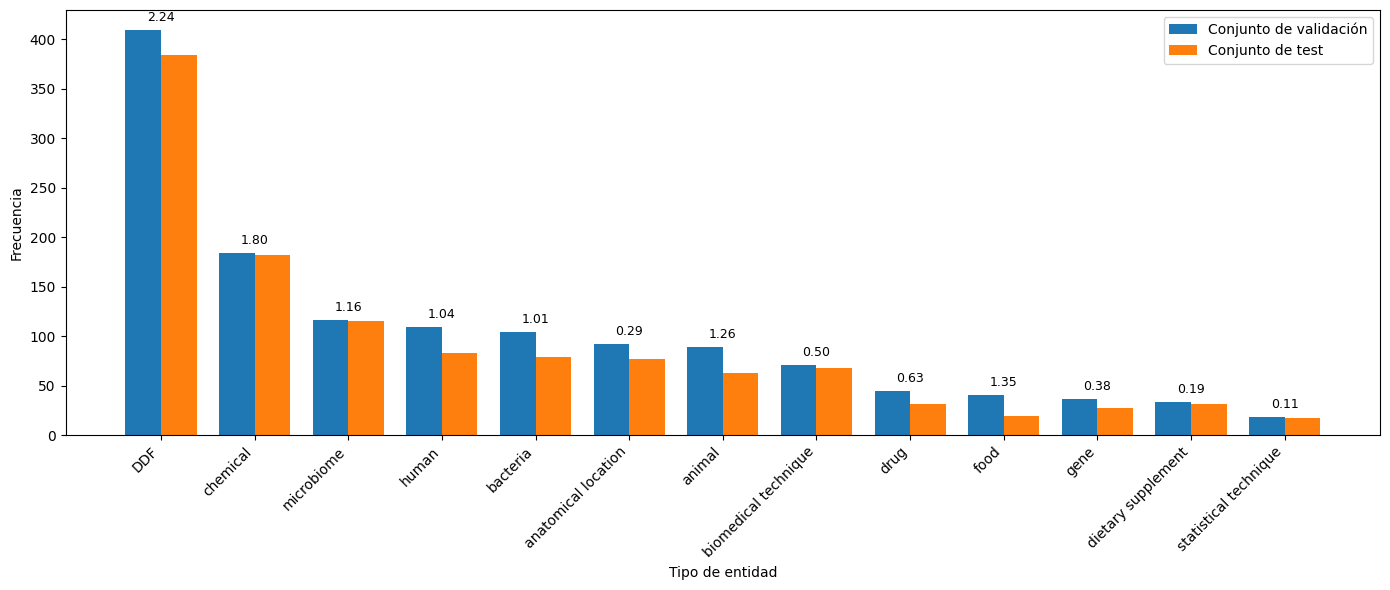

In [6]:
import matplotlib.pyplot as plt
import numpy as np

data = {
    'dietary supplement': (0.19, 33, 31),
    'DDF': (2.24, 409, 384),
    'microbiome': (1.16, 116, 115),
    'chemical': (1.8, 184, 182),
    'anatomical location': (0.29, 92, 77),
    'bacteria': (1.01, 104, 79),
    'animal': (1.26, 89, 63),
    'biomedical technique': (0.5, 71, 68),
    'gene': (0.38, 36, 27),
    'statistical technique': (0.11, 18, 17),
    'human': (1.04, 109, 83),
    'food': (1.35, 40, 19),
    'drug': (0.63, 44, 31)
}

# Ordenar por el segundo valor de la tupla, de mayor a menor
items = sorted(data.items(), key=lambda x: x[1][1], reverse=True)

labels = [item[0] for item in items]
scores = [item[1][0] for item in items]   # Primer valor de la tupla
values_1 = [item[1][1] for item in items] # Segundo valor
values_2 = [item[1][2] for item in items] # Tercer valor

x = np.arange(len(labels))
width = 0.38

plt.figure(figsize=(14, 6))

bars1 = plt.bar(
    x - width / 2,
    values_1,
    width,
    label="Conjunto de validación"
)

bars2 = plt.bar(
    x + width / 2,
    values_2,
    width,
    label="Conjunto de test"
)

# Poner encima de cada grupo el primer valor de la tupla
for i, score in enumerate(scores):
    max_height = max(values_1[i], values_2[i])
    plt.text(
        x[i],
        max_height + max(values_1 + values_2) * 0.015,
        f"{score:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xlabel("Tipo de entidad")
plt.ylabel("Frecuencia")

plt.xticks(x, labels, rotation=45, ha="right")
plt.legend()

plt.tight_layout()
plt.savefig("columnas_agrupadas_entidades.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
def count_labels(docs):

    counter = Counter()

    for doc in docs.values():

        for ent in doc["mention_level_relations"]:

            counter[ent["predicate"]] += 1

    return counter


print(count_labels(val_docs))
print(count_labels(test_docs))
def label_percentages(counter):

    total = sum(counter.values())

    return {
        k: (round(v / total * 100, 2),v)
        for k, v in sorted(counter.items())
    }

val_counter = count_labels(val_docs)
test_counter = count_labels(test_docs)

val_per = label_percentages(val_counter)
test_per = label_percentages(test_counter)
desviaciones = {}
for label, (perc, total) in val_per.items():
    diff = round(abs(perc - test_per[label][0]), 2)
    desviaciones[label] = (diff, total, test_per[label][1])
desviaciones

Counter({'located in': 96, 'affect': 71, 'target': 66, 'influence': 62, 'is linked to': 58, 'administered': 47, 'used by': 31, 'impact': 27, 'is a': 25, 'change effect': 19, 'interact': 18, 'part of': 17, 'strike': 12, 'change abundance': 10, 'change expression': 2, 'compared to': 1, 'produced by': 1})
Counter({'located in': 100, 'influence': 98, 'target': 78, 'affect': 54, 'is linked to': 52, 'used by': 42, 'impact': 30, 'administered': 25, 'is a': 22, 'interact': 20, 'part of': 13, 'change effect': 12, 'strike': 11, 'change abundance': 6, 'change expression': 5, 'produced by': 5, 'compared to': 3})


{'administered': (4.01, 47, 25),
 'affect': (3.23, 71, 54),
 'change abundance': (0.74, 10, 6),
 'change effect': (1.29, 19, 12),
 'change expression': (0.51, 2, 5),
 'compared to': (0.34, 1, 3),
 'impact': (0.41, 27, 30),
 'influence': (6.0, 62, 98),
 'interact': (0.27, 18, 20),
 'is a': (0.62, 25, 22),
 'is linked to': (1.27, 58, 52),
 'located in': (0.31, 96, 100),
 'part of': (0.76, 17, 13),
 'produced by': (0.69, 1, 5),
 'strike': (0.22, 12, 11),
 'target': (1.82, 66, 78),
 'used by': (1.78, 31, 42)}

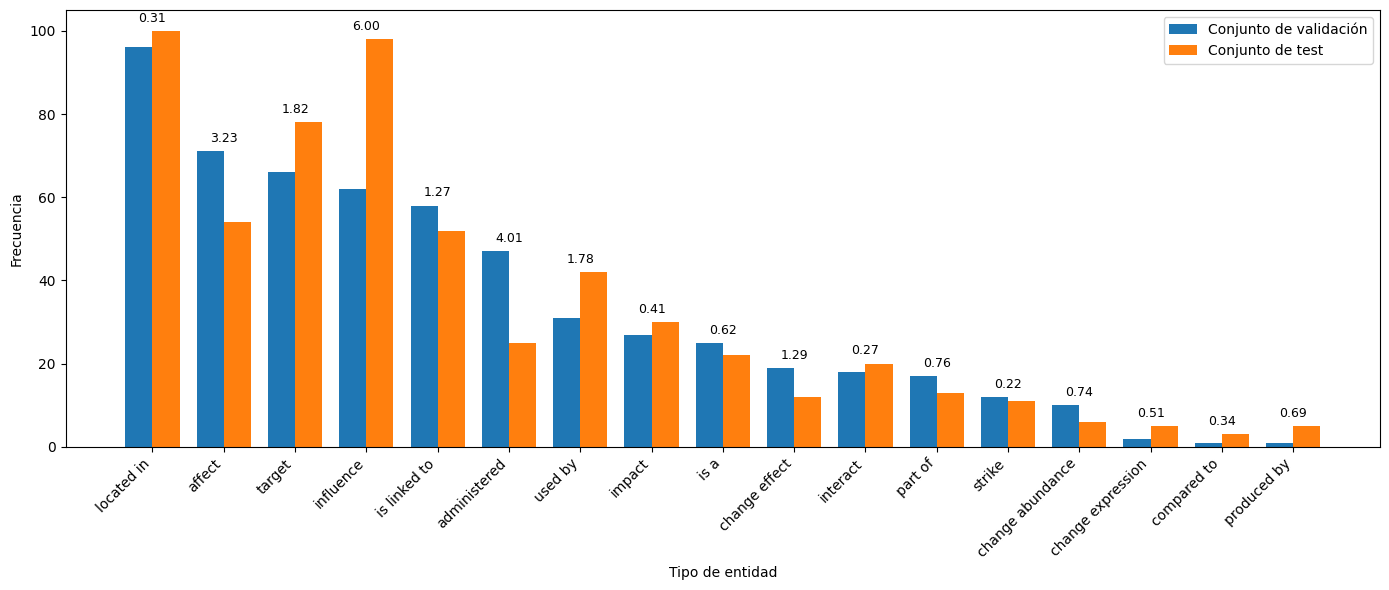

In [15]:
import numpy as np
import matplotlib.pyplot as plt
items = sorted(desviaciones.items(), key=lambda x: x[1][1], reverse=True)

labels = [item[0] for item in items]
scores = [item[1][0] for item in items]   # Primer valor de la tupla
values_1 = [item[1][1] for item in items] # Segundo valor
values_2 = [item[1][2] for item in items] # Tercer valor

x = np.arange(len(labels))
width = 0.38

plt.figure(figsize=(14, 6))

bars1 = plt.bar(
    x - width / 2,
    values_1,
    width,
    label="Conjunto de validación"
)

bars2 = plt.bar(
    x + width / 2,
    values_2,
    width,
    label="Conjunto de test"
)

# Poner encima de cada grupo el primer valor de la tupla
for i, score in enumerate(scores):
    max_height = max(values_1[i], values_2[i])
    plt.text(
        x[i],
        max_height + max(values_1 + values_2) * 0.015,
        f"{score:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xlabel("Tipo de entidad")
plt.ylabel("Frecuencia")

plt.xticks(x, labels, rotation=45, ha="right")
plt.legend()

plt.tight_layout()
plt.savefig("columnas_agrupadas_entidades.png", dpi=300, bbox_inches="tight")
plt.show()